In [39]:
import yfinance as yf
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [40]:
ticker = "AAPL"

start_date = "2018-01-01"
end_date = "2026-01-01"

stock = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

stock.head()

c:\Users\uzifl\Desktop\StockPredictor\backend\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\uzifl\Desktop\StockPredictor\backend\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\uzifl\Desktop\StockPredictor\backend\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inpl

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2018-01-02,40.232388,43.064999,43.075001,42.314999,42.540001,102223600
2018-01-03,40.225365,43.057499,43.637501,42.990002,43.132500,118071600
2018-01-04,40.412209,43.257500,43.367500,43.020000,43.134998,89738400
2018-01-05,40.872318,43.750000,43.842499,43.262501,43.360001,94640000
2018-01-08,40.720516,43.587502,43.902500,43.482498,43.587502,82271200


In [41]:
print("Dataset shape:", stock.shape)

print("\nDataset information:")
stock.info()

print("\nFirst five rows:")
display(stock.head())

print("\nLast five rows:")
display(stock.tail())

print("\nMissing values:")
display(stock.isnull().sum())

print("\nDuplicate dates:")
print(stock.index.duplicated().sum())

Dataset shape: (2011, 6)

Dataset information:
<class 'pandas.DataFrame'>
DatetimeIndex: 2011 entries, 2018-01-02 to 2025-12-31
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, AAPL)  2011 non-null   float64
 1   (Close, AAPL)      2011 non-null   float64
 2   (High, AAPL)       2011 non-null   float64
 3   (Low, AAPL)        2011 non-null   float64
 4   (Open, AAPL)       2011 non-null   float64
 5   (Volume, AAPL)     2011 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 110.0 KB

First five rows:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2018-01-02,40.232388,43.064999,43.075001,42.314999,42.540001,102223600
2018-01-03,40.225365,43.057499,43.637501,42.990002,43.132500,118071600
2018-01-04,40.412209,43.257500,43.367500,43.020000,43.134998,89738400
2018-01-05,40.872318,43.750000,43.842499,43.262501,43.360001,94640000
2018-01-08,40.720516,43.587502,43.902500,43.482498,43.587502,82271200



Last five rows:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2025-12-24,273.066742,273.809998,275.429993,272.200012,272.339996,17910600
2025-12-26,272.657806,273.399994,275.369995,272.859985,274.160004,21521800
2025-12-29,273.016876,273.760010,274.359985,272.350006,272.690002,23715200
2025-12-30,272.338684,273.079987,274.079987,272.279999,272.809998,22139600
2025-12-31,271.122009,271.859985,273.679993,271.750000,273.059998,27293600



Missing values:


Price      Ticker
Adj Close  AAPL      0
Close      AAPL      0
High       AAPL      0
Low        AAPL      0
Open       AAPL      0
Volume     AAPL      0
dtype: int64


Duplicate dates:
0


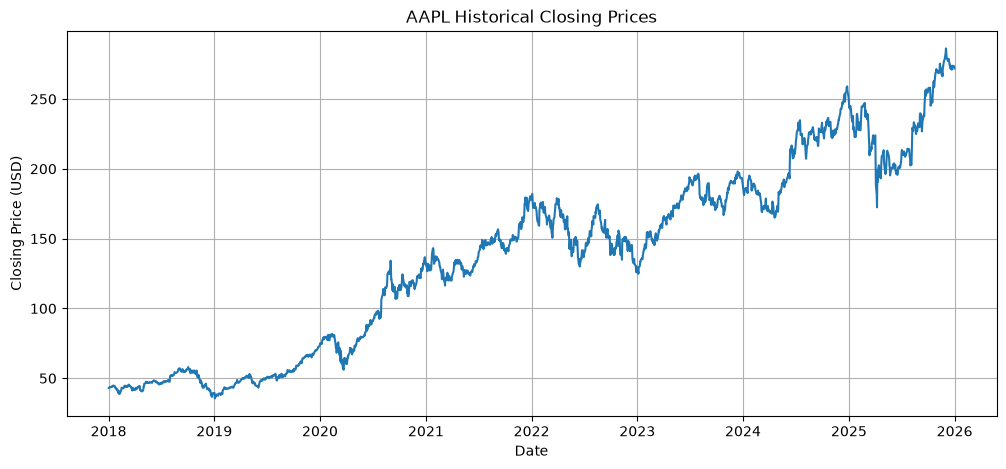

In [42]:
# Visualize
plt.figure(figsize=(12, 5))

plt.plot(stock.index, stock["Close"])

plt.title("AAPL Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)

plt.show()

In [43]:
df = stock.copy()

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Remove unnecessary column index metadata
df.columns.name = None

print(df.columns.tolist())

['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [44]:
# check for missing values
print("Missing values:")
print(df.isna().sum().to_string())

# check for dupes
duplicates = df.index.duplicated().sum()
print(f"\nDuplicate dates: {duplicates}")

# check if dates are sorted
print(f"\nDates sorted: {df.index.is_monotonic_increasing}")

# check for invalid prices
price_columns = ["Open", "High", "Low", "Close"]

invalid_prices = (df[price_columns] <= 0).sum()

print("Invalid prices: ")
print(invalid_prices)

Missing values:
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0

Duplicate dates: 0

Dates sorted: True
Invalid prices: 
Open     0
High     0
Low      0
Close    0
dtype: int64


In [45]:
# OHLC consistency validation

invalid_high = (
    df["High"] < df[["Open", "Close"]].max(axis=1)
).sum()

invalid_low = (
    df["Low"] > df[["Open", "Close"]].min(axis=1)
).sum()

print("Invalid high values:", invalid_high)
print("Invalid low values:", invalid_low)

Invalid high values: 0
Invalid low values: 0


In [46]:
# FINAL QUALITY REPORT

print("===== DATA QUALITY REPORT =====")

print(f"Ticker: {ticker}")
print(f"Observations: {len(df)}")
print(f"Start date: {df.index.min()}")
print(f"End date: {df.index.max()}")

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate dates:", df.index.duplicated().sum())

print("\nChronologically sorted:", df.index.is_monotonic_increasing)

print("\nInvalid prices:")
print((df[price_columns] <= 0).sum())

print("\nInvalid high values:", invalid_high)
print("Invalid low values:", invalid_low)

===== DATA QUALITY REPORT =====
Ticker: AAPL
Observations: 2011
Start date: 2018-01-02 00:00:00
End date: 2025-12-31 00:00:00

Missing values:
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Duplicate dates: 0

Chronologically sorted: True

Invalid prices:
Open     0
High     0
Low      0
Close    0
dtype: int64

Invalid high values: 0
Invalid low values: 0


In [47]:
# check if volume is neg, if high is below low, or if numeric vals are non-finite

import numpy as np

numeric_columns = [
    "Open", "High", "Low", "Close", "Volume"
]

print("Negative volume:", (df["Volume"] < 0).sum())

print("High below Low:", (df["High"] < df["Low"]).sum())

print(
    "Non-finite numeric values:",
    (~np.isfinite(df[numeric_columns].to_numpy())).sum()
)

Negative volume: 0
High below Low: 0
Non-finite numeric values: 0


In [48]:
from pathlib import Path

data_dir = Path("../data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

csv_path = data_dir / "AAPL_2018_2025.csv"

df.to_csv(csv_path, index_label="Date")

print(f"Dataset saved to: {csv_path.resolve()}")

Dataset saved to: C:\Users\uzifl\Desktop\StockPredictor\backend\data\raw\AAPL_2018_2025.csv


In [49]:
import json
from datetime import datetime, timezone

metadata_dir = Path("../data/metadata")
metadata_dir.mkdir(parents=True, exist_ok=True)

metadata = {
    "ticker": ticker,
    "source": "Yahoo Finance via yfinance",
    "requested_start": start_date,
    "requested_end_exclusive": end_date,
    "actual_start": str(df.index.min().date()),
    "actual_end": str(df.index.max().date()),
    "observations": len(df),
    "columns": df.columns.tolist(),
    "auto_adjust": False,
    "downloaded_at_utc": datetime.now(timezone.utc).isoformat()
}

metadata_path = metadata_dir / "AAPL_2018_2025.json"

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved successfully.")

Metadata saved successfully.


In [50]:
# Reload the saved CSV
loaded_df = pd.read_csv(
    csv_path,
    index_col="Date",
    parse_dates=True
)

# Inspect the reloaded dataset
print("Original shape:", df.shape)
print("Loaded shape:", loaded_df.shape)

print("\nOriginal columns:")
print(df.columns.tolist())

print("\nLoaded columns:")
print(loaded_df.columns.tolist())

display(loaded_df.head())

Original shape: (2011, 6)
Loaded shape: (2011, 6)

Original columns:
['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']

Loaded columns:
['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2018-01-02,40.232388,43.064999,43.075001,42.314999,42.540001,102223600
2018-01-03,40.225365,43.057499,43.637501,42.990002,43.132500,118071600
2018-01-04,40.412209,43.257500,43.367500,43.020000,43.134998,89738400
2018-01-05,40.872318,43.750000,43.842499,43.262501,43.360001,94640000
2018-01-08,40.720516,43.587502,43.902500,43.482498,43.587502,82271200


In [51]:
# Create copies for comparison
original = df.copy()
reloaded = loaded_df.copy()

# Normalize datetime index resolution
original.index = pd.to_datetime(original.index).as_unit("ns")
reloaded.index = pd.to_datetime(reloaded.index).as_unit("ns")

# Standardize index names
original.index.name = "Date"
reloaded.index.name = "Date"

# Standardize column index names
original.columns.name = None
reloaded.columns.name = None

# Verify datasets match
pd.testing.assert_frame_equal(
    original,
    reloaded,
    check_freq=False,
    check_exact=False,
    rtol=1e-10,
    atol=1e-10
)

print("Dataset successfully saved and reloaded!")

Dataset successfully saved and reloaded!
